# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Dennis Ardiyansyah
- **Email:** ds296b6y0424@student.devacademy.id
- **ID Dicoding:** ds296b6y0424

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Apa saja 10 kategori produk dengan total pendapatan (harga barang, tanpa ongkir) tertinggi dari pesanan yang terkirim selama Januari 2017–Agustus 2018, dan bagaimana tren pendapatan bulanan 5 kategori teratas pada periode tersebut, sebagai dasar menentukan kategori prioritas untuk stok dan promosi?
- **Pertanyaan 2:** Negara bagian (*state*) pelanggan mana yang memiliki persentase pesanan terlambat (diterima melewati estimasi) dan rata-rata waktu pengiriman tertinggi selama Januari 2017–Agustus 2018, serta berapa selisih rata-rata skor ulasan antara pesanan terlambat dan tepat waktu, sebagai dasar memilih wilayah yang perlu perbaikan logistik lebih dulu?

## Import Semua Packages/Library yang Digunakan

In [76]:
import os
import shutil
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import folium

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Warna konsisten untuk semua visualisasi:
# biru untuk data yang ditonjolkan, abu-abu untuk konteks, merah untuk masalah.
MAIN_COLOR = "#1F6F8B"
GREY = "#C8C8C8"
ALERT = "#D1495B"

## Data Wrangling

### Gathering Data

#### Load dataset dari Google Drive Dicoding

In [77]:
# Dataset terdiri dari 9 tabel CSV; analisis ini memakai 8 tabel (tabel sellers tidak dipakai
# karena kedua pertanyaan bisnis berfokus pada sisi pelanggan).
DATA_DIR = "data"
FILES = {
    "customers": "customers_dataset.csv",
    "orders": "orders_dataset.csv",
    "order_items": "order_items_dataset.csv",
    "order_payments": "order_payments_dataset.csv",
    "order_reviews": "order_reviews_dataset.csv",
    "products": "products_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "geolocation": "geolocation_dataset.csv",
}

if not os.path.exists(os.path.join(DATA_DIR, FILES["orders"])):
    import gdown

    gdown.download(id="1MsAjPM7oKtVfJL_wRp1qmCajtSG1mdcK", output="ecommerce.zip", quiet=False)
    with zipfile.ZipFile("ecommerce.zip") as zf:
        zf.extractall("tmp_dataset")
    os.makedirs(DATA_DIR, exist_ok=True)
    for root, _, files in os.walk("tmp_dataset"):
        for f in files:
            if f.endswith(".csv"):
                shutil.move(os.path.join(root, f), os.path.join(DATA_DIR, f))
    shutil.rmtree("tmp_dataset", ignore_errors=True)

print(sorted(os.listdir(DATA_DIR)))

['customers_dataset.csv', 'geolocation_dataset.csv', 'order_items_dataset.csv', 'order_payments_dataset.csv', 'order_reviews_dataset.csv', 'orders_dataset.csv', 'product_category_name_translation.csv', 'products_dataset.csv', 'sellers_dataset.csv']


#### Load tabel orders

In [78]:
orders_df = pd.read_csv(os.path.join(DATA_DIR, FILES["orders"]))
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load tabel order_items

In [79]:
order_items_df = pd.read_csv(os.path.join(DATA_DIR, FILES["order_items"]))
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load tabel order_payments

In [80]:
payments_df = pd.read_csv(os.path.join(DATA_DIR, FILES["order_payments"]))
payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


#### Load tabel order_reviews

In [81]:
reviews_df = pd.read_csv(os.path.join(DATA_DIR, FILES["order_reviews"]))
reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load tabel customers

In [82]:
# Kode pos dibaca sebagai teks agar angka nol di depan (misal 01037) tidak hilang
customers_df = pd.read_csv(os.path.join(DATA_DIR, FILES["customers"]), dtype={"customer_zip_code_prefix": str})
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load tabel products dan terjemahan kategori

In [83]:
products_df = pd.read_csv(os.path.join(DATA_DIR, FILES["products"]))
category_df = pd.read_csv(os.path.join(DATA_DIR, FILES["category_translation"]), encoding="utf-8-sig")
display(products_df.head())
category_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


#### Load tabel geolocation

In [84]:
geolocation_df = pd.read_csv(os.path.join(DATA_DIR, FILES["geolocation"]), dtype={"geolocation_zip_code_prefix": str})
geolocation_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,01037,-23.55,-46.64,sao paulo,SP
1,01046,-23.55,-46.64,sao paulo,SP
2,01046,-23.55,-46.64,sao paulo,SP
3,01041,-23.54,-46.64,sao paulo,SP
4,01035,-23.54,-46.64,sao paulo,SP


**Insight:**

- Data terdiri dari 8 tabel yang saling terhubung melalui ID pesanan, pelanggan, produk, dan kode pos.
- `orders_df` menjadi tabel utama dengan 99.441 pesanan, sedangkan `order_items_df` memiliki 112.650 baris karena satu pesanan bisa berisi beberapa barang.
- Nama kategori produk diterjemahkan dari bahasa Portugis agar lebih mudah dipahami.
- Kode pos disimpan sebagai teks agar angka nol di depannya tidak hilang.

### Assessing Data

#### Identifying gambaran umum kualitas semua tabel

In [85]:
tables = {
    "orders_df": orders_df, "order_items_df": order_items_df, "payments_df": payments_df,
    "reviews_df": reviews_df, "customers_df": customers_df, "products_df": products_df,
    "category_df": category_df, "geolocation_df": geolocation_df,
}
pd.DataFrame({
    name: {
        "baris": len(df),
        "missing_total": int(df.isna().sum().sum()),
        "duplikat": int(df.duplicated().sum()),
    }
    for name, df in tables.items()
}).T

,baris,missing_total,duplikat
orders_df,99441,4908,0
order_items_df,112650,0,0
payments_df,103886,0,0
reviews_df,99224,145903,0
customers_df,99441,0,0
products_df,32951,2448,0
category_df,71,0,0
geolocation_df,1000163,0,261831


**Steps to Take:**
- Periksa lebih lanjut data kosong pada `orders_df`, `products_df`, dan `reviews_df`, serta data duplikat pada `geolocation_df`.
- Kolom komentar ulasan boleh kosong karena tidak semua pelanggan memberikan komentar dan kolom ini tidak digunakan dalam analisis.

#### Identifying tipe data tanggal yang salah

In [86]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


**Steps to Take:**
- Ubah kolom tanggal pada `orders_df`, `order_items_df`, dan `reviews_df` dari teks menjadi format `datetime` agar bisa diolah sebagai tanggal.

#### Identifying missing value pada orders_df

In [87]:
print(orders_df.isna().sum())
print()
print("Status pesanan yang tanggal diterimanya kosong:")
print(orders_df[orders_df["order_delivered_customer_date"].isna()]["order_status"].value_counts())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Status pesanan yang tanggal diterimanya kosong:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


**Steps to Take:**
- Sebagian besar tanggal penerimaan yang kosong berasal dari pesanan yang belum atau tidak sampai, sehingga bukan kesalahan data.
- Ada 8 pesanan berstatus `delivered` tanpa tanggal penerimaan. Analisis hanya menggunakan pesanan dengan tanggal lengkap tanpa menambahkan tanggal perkiraan.

#### Identifying missing value dan inconsistent value pada products_df

In [88]:
print(products_df.isna().sum())
print()
kategori_tanpa_terjemahan = set(products_df["product_category_name"].dropna()) - set(category_df["product_category_name"])
print("Kategori tanpa terjemahan:", kategori_tanpa_terjemahan)

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


**Steps to Take:**
- Isi 610 kategori kosong dengan `unknown` karena data harga masih bisa digunakan.
- Tambahkan terjemahan untuk 2 kategori yang belum tersedia.
- Biarkan 2 data dimensi produk yang kosong karena tidak digunakan dalam analisis.

#### Identifying duplicate data pada reviews_df

In [89]:
print("order_id yang muncul lebih dari sekali:", reviews_df["order_id"].duplicated().sum())
reviews_df[reviews_df["order_id"].duplicated(keep=False)].sort_values("order_id").head(4)

order_id yang muncul lebih dari sekali: 551


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,NaN,NaN,2017-08-29 00:00:00,2017-08-30 01:59:12
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,NaN,Estou acostumada a comprar produtos pelo barat...,2017-08-25 00:00:00,2017-08-29 21:45:57
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,NaN,NaN,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,NaN,NaN,2018-03-04 00:00:00,2018-03-05 17:02:00


**Steps to Take:**
- Gunakan ulasan terbaru untuk setiap pesanan dan hapus ulasan lainnya agar satu pesanan hanya memiliki satu skor ulasan.

#### Identifying duplicate data dan inaccurate value pada geolocation_df

In [90]:
print("Baris duplikat:", geolocation_df.duplicated().sum())

# Batas kasar wilayah Brasil: lintang -34 s.d. 5,3 dan bujur -74 s.d. -34
di_luar_brasil = ~geolocation_df["geolocation_lat"].between(-34, 5.3) | ~geolocation_df["geolocation_lng"].between(-74, -34)
print("Koordinat di luar wilayah Brasil:", di_luar_brasil.sum())
geolocation_df[di_luar_brasil].head()

Baris duplikat: 261831
Koordinat di luar wilayah Brasil: 42


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.01,-15.54,bom retiro da esperanca,SP
513631,28165,41.61,-8.41,vila nova de campos,RJ
513643,28155,-34.59,-58.73,santa maria,RJ
513754,28155,42.44,13.82,santa maria,RJ
514429,28333,38.38,-6.33,raposo,RJ


**Steps to Take:**
- Hapus data yang duplikat.
- Hapus koordinat yang berada di luar wilayah Brasil karena seluruh pelanggan Olist berasal dari Brasil.
- Hitung rata-rata koordinat untuk setiap kode pos karena satu kode pos dapat memiliki beberapa titik lokasi.

#### Identifying invalid value pada payments_df

In [91]:
print(payments_df["payment_type"].value_counts())
print()
print("payment_value = 0:", (payments_df["payment_value"] == 0).sum())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

payment_value = 0: 9


**Steps to Take:**
- Hapus 3 transaksi dengan tipe pembayaran `not_defined` karena tidak valid.
- Pertahankan `payment_value = 0` karena dapat terjadi pada pembayaran yang sepenuhnya menggunakan voucher.

#### Identifying outlier pada harga dan ongkir

In [92]:
def jumlah_outlier_iqr(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()

print(order_items_df[["price", "freight_value"]].describe())
print()
print("Outlier price (IQR):", jumlah_outlier_iqr(order_items_df["price"]))
print("Outlier freight_value (IQR):", jumlah_outlier_iqr(order_items_df["freight_value"]))

           price  freight_value
count 112,650.00     112,650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max     6,735.00         409.68

Outlier price (IQR): 8427
Outlier freight_value (IQR): 12134


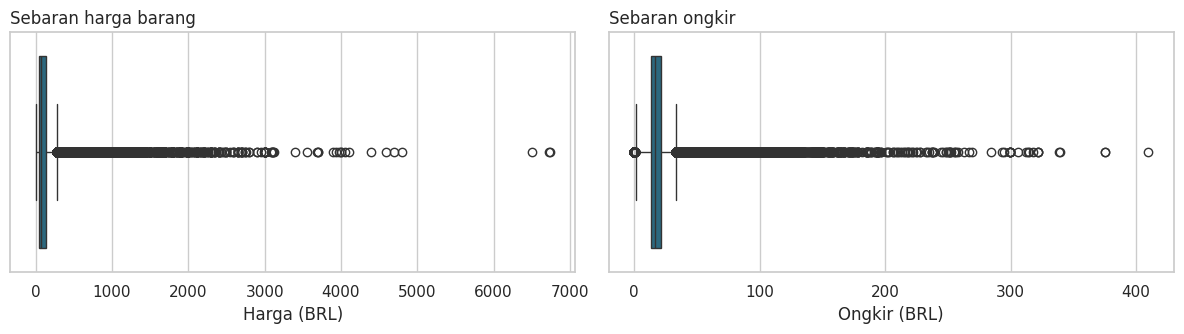

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=order_items_df["price"], color=MAIN_COLOR, ax=axes[0])
axes[0].set_title("Sebaran harga barang", loc="left")
axes[0].set_xlabel("Harga (BRL)")
sns.boxplot(x=order_items_df["freight_value"], color=MAIN_COLOR, ax=axes[1])
axes[1].set_title("Sebaran ongkir", loc="left")
axes[1].set_xlabel("Ongkir (BRL)")
plt.tight_layout()
plt.show()

**Steps to Take:**
- Pertahankan data harga dan ongkir yang ekstrem karena merupakan transaksi asli, bukan kesalahan input. Menghapusnya dapat menyebabkan hilangnya data pendapatan yang sebenarnya.

#### Identifying periode data yang tidak lengkap

In [94]:
pesanan_per_bulan = orders_df.groupby(pd.to_datetime(orders_df["order_purchase_timestamp"]).dt.to_period("M")).size()
pesanan_per_bulan

,0
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


**Steps to Take:**
- Data pada 2016 dan September–Oktober 2018 masih sangat sedikit sehingga dapat membuat perbandingan bulanan kurang akurat.
- Batasi analisis pada Januari 2017–Agustus 2018 agar menggunakan 20 bulan dengan data yang lebih lengkap.

**Insight:**

| No | Tabel | Masalah | Jenis | Tindakan di tahap Cleaning |
|---|---|---|---|---|
| 1 | `orders_df`, `order_items_df`, `reviews_df` | Kolom tanggal bertipe `object` | Tipe data salah | Ubah ke `datetime` |
| 2 | `orders_df` | 2.965 tanggal diterima kosong; 8 pesanan `delivered` tanpa tanggal diterima | Missing value | Pakai hanya pesanan `delivered` yang tanggalnya lengkap |
| 3 | `products_df` | 610 produk tanpa kategori | Missing value | Isi dengan `unknown` |
| 4 | `products_df` vs `category_df` | 2 kategori tanpa terjemahan | Inconsistent value | Tambah terjemahan manual |
| 5 | `reviews_df` | 551 pesanan punya lebih dari satu ulasan | Duplicate data | Simpan ulasan terbaru |
| 6 | `geolocation_df` | 261.831 baris duplikat dan koordinat di luar Brasil | Duplicate & inaccurate value | Hapus duplikat, buang koordinat di luar Brasil |
| 7 | `payments_df` | 3 transaksi `not_defined` | Invalid value | Hapus |
| 8 | `order_items_df` | Outlier harga dan ongkir | Outlier | Dipertahankan (transaksi asli) |
| 9 | `orders_df` | Bulan-bulan dengan data tidak lengkap | Incomplete data | Batasi periode ke Januari 2017–Agustus 2018 |

### Cleaning Data

#### Fixing tipe data tanggal

In [95]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])
for col in ["review_creation_date", "review_answer_timestamp"]:
    reviews_df[col] = pd.to_datetime(reviews_df[col])

# Test: semua kolom tanggal sudah bertipe datetime
orders_df[date_cols].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


#### Fixing rentang periode analisis

In [96]:
START, END = "2017-01-01", "2018-09-01"
orders_df = orders_df[(orders_df["order_purchase_timestamp"] >= START) & (orders_df["order_purchase_timestamp"] < END)]

# Test
print("Rentang setelah dibatasi:", orders_df["order_purchase_timestamp"].min().date(), "s.d.", orders_df["order_purchase_timestamp"].max().date())
print("Jumlah pesanan:", len(orders_df))

Rentang setelah dibatasi: 2017-01-05 s.d. 2018-08-31
Jumlah pesanan: 99092


#### Fixing missing value dan inconsistent value pada kategori produk

In [97]:
tambahan = pd.DataFrame({
    "product_category_name": ["portateis_cozinha_e_preparadores_de_alimentos", "pc_gamer"],
    "product_category_name_english": ["portable_kitchen_food_preparers", "pc_gamer"],
})
category_df = pd.concat([category_df, tambahan], ignore_index=True)

products_df = products_df.merge(category_df, how="left", on="product_category_name")
products_df["product_category"] = products_df["product_category_name_english"].fillna("unknown")

# Test
print("Kategori kosong di kolom baru:", products_df["product_category"].isna().sum())
print("Produk berkategori 'unknown':", (products_df["product_category"] == "unknown").sum())
print("Kategori asli tanpa terjemahan:",
      (products_df["product_category_name"].notna() & products_df["product_category_name_english"].isna()).sum())

Kategori kosong di kolom baru: 0
Produk berkategori 'unknown': 610
Kategori asli tanpa terjemahan: 0


#### Fixing duplicate data pada reviews_df

In [98]:
reviews_df = (
    reviews_df.sort_values("review_answer_timestamp")
    .drop_duplicates(subset="order_id", keep="last")
)

# Test
print("order_id ganda di reviews_df:", reviews_df["order_id"].duplicated().sum())

order_id ganda di reviews_df: 0


#### Fixing invalid value pada payments_df

In [99]:
payments_df = payments_df[payments_df["payment_type"] != "not_defined"]

# Test
print(payments_df["payment_type"].value_counts())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
Name: count, dtype: int64


#### Fixing duplicate data dan inaccurate value pada geolocation_df

In [100]:
geolocation_df = geolocation_df.drop_duplicates()
geolocation_df = geolocation_df[
    geolocation_df["geolocation_lat"].between(-34, 5.3)
    & geolocation_df["geolocation_lng"].between(-74, -34)
]

# Test
print("Baris duplikat tersisa:", geolocation_df.duplicated().sum())
print("Rentang lintang:", round(geolocation_df["geolocation_lat"].min(), 2), "s.d.", round(geolocation_df["geolocation_lat"].max(), 2))
print("Rentang bujur  :", round(geolocation_df["geolocation_lng"].min(), 2), "s.d.", round(geolocation_df["geolocation_lng"].max(), 2))

# Satu kode pos punya banyak titik; ambil rata-ratanya sebagai titik pusat kode pos
geo_zip_df = (
    geolocation_df.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
    .mean()
    .reset_index()
)
print("Kode pos unik dengan koordinat valid:", len(geo_zip_df))

Baris duplikat tersisa: 0
Rentang lintang: -33.69 s.d. 4.48
Rentang bujur  : -72.93 s.d. -34.79
Kode pos unik dengan koordinat valid: 19010


#### Fixing struktur data: menggabungkan tabel menjadi data siap analisis

In [101]:
# Data tingkat pesanan: hanya pesanan terkirim yang tanggal diterimanya lengkap
delivered_df = orders_df[
    (orders_df["order_status"] == "delivered") & orders_df["order_delivered_customer_date"].notna()
].copy()

delivered_df["delivery_days"] = (
    delivered_df["order_delivered_customer_date"] - delivered_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400
# Terlambat = tanggal diterima melewati tanggal estimasi
delivered_df["is_late"] = (
    delivered_df["order_delivered_customer_date"].dt.normalize() > delivered_df["order_estimated_delivery_date"]
)

payment_per_order = payments_df.groupby("order_id")["payment_value"].sum().rename("payment_value")

order_df = (
    delivered_df
    .merge(customers_df, on="customer_id", how="left")
    .merge(reviews_df[["order_id", "review_score"]], on="order_id", how="left")
    .merge(payment_per_order, on="order_id", how="left")
)

# Data tingkat barang: untuk analisis kategori
item_df = (
    order_items_df
    .merge(order_df[["order_id", "order_purchase_timestamp", "customer_unique_id", "customer_state"]], on="order_id", how="inner")
    .merge(products_df[["product_id", "product_category"]], on="product_id", how="left")
)

# Test
print("order_df:", order_df.shape)
print("item_df :", item_df.shape)
print("\nMissing value penting di order_df:")
print(order_df[["customer_state", "delivery_days", "review_score", "payment_value"]].isna().sum())

order_df: (96203, 16)
item_df : (109872, 11)

Missing value penting di order_df:
customer_state      0
delivery_days       0
review_score      643
payment_value       0
dtype: int64


**Insight:**
- Semua kolom tanggal sudah menggunakan format `datetime`, sehingga lama pengiriman dan data bulanan dapat dihitung.
- Setiap perbaikan sudah diuji ulang. Tidak ditemukan lagi ulasan ganda, kategori yang belum diterjemahkan, jenis pembayaran tidak valid, data duplikat, maupun koordinat di luar Brasil.
- Setelah pembersihan, tersisa 96.203 pesanan terkirim (`order_df`) dan 109.872 baris barang (`item_df`).
- Tambahkan dua kolom, yaitu `delivery_days` untuk menghitung lama pengiriman dan `is_late` untuk menandai pesanan yang terlambat.
- Sebanyak 643 pesanan tidak memiliki ulasan. Data tetap dipertahankan karena Pandas otomatis mengabaikan nilai kosong saat menghitung rata-rata.

## Exploratory Data Analysis (EDA)

### Explore parameter statistik dan distribusi data pesanan

In [102]:
order_df[["delivery_days", "payment_value", "review_score"]].describe()

,delivery_days,payment_value,review_score
count,"96,203.00","96,203.00","95,560.00"
mean,12.54,159.81,4.16
std,9.53,218.89,1.28
min,0.53,9.59,1.00
25%,6.76,61.88,4.00
50%,10.21,105.28,5.00
75%,15.68,176.26,5.00
max,209.63,"13,664.08",5.00


Skewness:
delivery_days   3.85
payment_value   9.38
dtype: float64


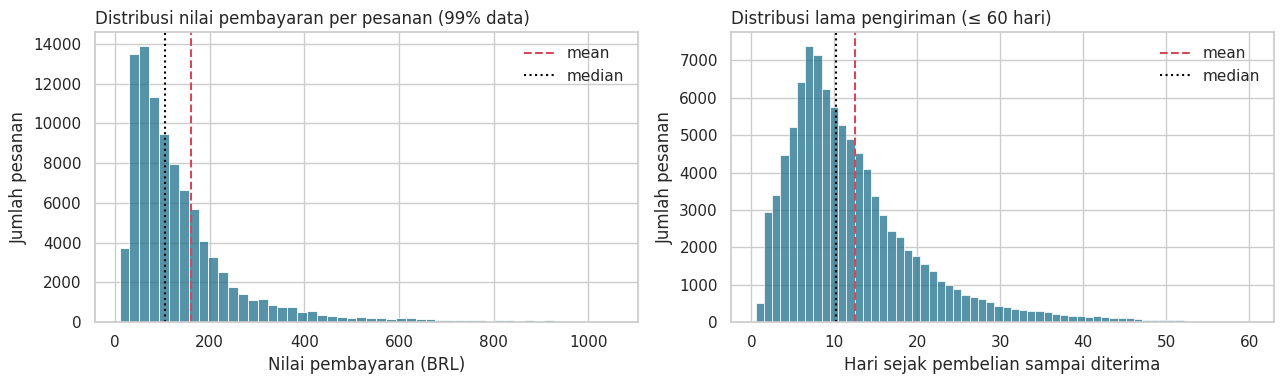

In [103]:
print("Skewness:")
print(order_df[["delivery_days", "payment_value"]].skew().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
batas = order_df["payment_value"].quantile(0.99)
sns.histplot(order_df.loc[order_df["payment_value"] <= batas, "payment_value"], bins=50, color=MAIN_COLOR, ax=axes[0])
axes[0].axvline(order_df["payment_value"].mean(), color=ALERT, linestyle="--", label="mean")
axes[0].axvline(order_df["payment_value"].median(), color="black", linestyle=":", label="median")
axes[0].set_title("Distribusi nilai pembayaran per pesanan (99% data)", loc="left")
axes[0].set_xlabel("Nilai pembayaran (BRL)")
axes[0].set_ylabel("Jumlah pesanan")
axes[0].legend(frameon=False)

sns.histplot(order_df.loc[order_df["delivery_days"] <= 60, "delivery_days"], bins=60, color=MAIN_COLOR, ax=axes[1])
axes[1].axvline(order_df["delivery_days"].mean(), color=ALERT, linestyle="--", label="mean")
axes[1].axvline(order_df["delivery_days"].median(), color="black", linestyle=":", label="median")
axes[1].set_title("Distribusi lama pengiriman (≤ 60 hari)", loc="left")
axes[1].set_xlabel("Hari sejak pembelian sampai diterima")
axes[1].set_ylabel("Jumlah pesanan")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

**Insight:**

- Rata-rata pembayaran sekitar 160 BRL, sedangkan nilai tengahnya 105 BRL. Artinya, sebagian besar pesanan bernilai kecil, tetapi beberapa pesanan bernilai besar membuat rata-rata meningkat.
- Sebagian besar pesanan tiba dalam 1–2 minggu, dengan waktu pengiriman tengah sekitar 10 hari. Namun, ada juga pesanan yang membutuhkan waktu lebih dari 200 hari.
- Rata-rata skor ulasan mencapai 4,16 dari 5. Namun, angka ini belum menunjukkan kelompok pelanggan yang memberikan penilaian rendah.

### Explore tren pesanan dan pendapatan bulanan

In [104]:
monthly_df = item_df.groupby(item_df["order_purchase_timestamp"].dt.to_period("M")).agg(
    jumlah_pesanan=("order_id", "nunique"),
    pendapatan=("price", "sum"),
)
monthly_df

,jumlah_pesanan,pendapatan
order_purchase_timestamp,,
2017-01,750,"111,798.36"
2017-02,1653,"234,223.40"
2017-03,2546,"359,198.85"
2017-04,2303,"340,669.68"
2017-05,3545,"489,159.25"
2017-06,3135,"421,923.37"
2017-07,3872,"481,604.52"
2017-08,4193,"554,699.70"
2017-09,4150,"607,399.67"


**Insight:**
- Jumlah pesanan meningkat sepanjang 2017 dan mencapai puncaknya pada November 2017 saat Black Friday dengan 7.288 pesanan. Pada 2018, jumlah pesanan stabil di kisaran 6–7 ribu per bulan.

### Explore pendapatan per kategori produk

In [105]:
category_summary = item_df.groupby("product_category").agg(
    pendapatan=("price", "sum"),
    jumlah_pesanan=("order_id", "nunique"),
    barang_terjual=("order_item_id", "count"),
    harga_rata2=("price", "mean"),
).sort_values("pendapatan", ascending=False)
category_summary["porsi_pendapatan_%"] = category_summary["pendapatan"] / category_summary["pendapatan"].sum() * 100

print("Jumlah kategori:", len(category_summary))
print(f"Porsi 10 kategori teratas: {category_summary['porsi_pendapatan_%'].head(10).sum():.1f}% dari total pendapatan")
category_summary.head(10)

Jumlah kategori: 74
Porsi 10 kategori teratas: 62.5% dari total pendapatan


,pendapatan,jumlah_pesanan,barang_terjual,harga_rata2,porsi_pendapatan_%
product_category,,,,,
health_beauty,"1,229,557.50",8610,9422,130.50,9.33
watches_gifts,"1,163,187.91",5489,5853,198.73,8.83
bed_bath_table,"1,022,955.77",9267,10945,93.46,7.76
sports_leisure,"952,661.40",7512,8413,113.24,7.23
computers_accessories,"887,944.60",6517,7631,116.36,6.74
furniture_decor,"706,237.17",6258,8095,87.24,5.36
housewares,"614,341.62",5734,6783,90.57,4.66
cool_stuff,"609,158.00",3552,3711,164.15,4.62
auto,"577,721.09",3801,4131,139.85,4.38


In [106]:
top5_categories = category_summary.head(5).index.tolist()
item_df["tahun"] = item_df["order_purchase_timestamp"].dt.year
item_df["bulan_ke"] = item_df["order_purchase_timestamp"].dt.month

# Bandingkan Januari–Agustus 2017 dengan Januari–Agustus 2018 agar periodenya setara
jan_aug = item_df[item_df["bulan_ke"] <= 8]
growth_df = jan_aug[jan_aug["product_category"].isin(top5_categories)].pivot_table(
    index="product_category", columns="tahun", values="price", aggfunc="sum"
)
growth_df["pertumbuhan_%"] = (growth_df[2018] / growth_df[2017] - 1) * 100
growth_df.sort_values("pertumbuhan_%", ascending=False)

tahun,2017,2018,pertumbuhan_%
product_category,,,
watches_gifts,"201,137.86","687,577.20",241.84
health_beauty,"243,521.70","755,724.50",210.33
sports_leisure,"216,545.33","517,166.26",138.83
computers_accessories,"214,631.27","496,158.31",131.17
bed_bath_table,"254,444.82","532,358.85",109.22


**Insight:**

- Dari 74 kategori, 10 kategori teratas menghasilkan 62,5% dari total pendapatan.
- `health_beauty` menjadi penyumbang pendapatan terbesar, diikuti `watches_gifts`. Meski jumlah pesanannya lebih sedikit, `watches_gifts` memiliki harga rata-rata lebih tinggi.
- Kelima kategori teratas mengalami peningkatan pendapatan pada Januari–Agustus 2018 dibandingkan periode yang sama pada 2017. Pertumbuhan tertinggi terjadi pada `watches_gifts` dan `health_beauty`, sedangkan `bed_bath_table` paling rendah.

### Explore kinerja pengiriman per negara bagian

In [107]:
state_summary = order_df.groupby("customer_state").agg(
    jumlah_pesanan=("order_id", "count"),
    rata2_hari_kirim=("delivery_days", "mean"),
    persen_terlambat=("is_late", "mean"),
    rata2_skor_ulasan=("review_score", "mean"),
)
state_summary["persen_terlambat"] *= 100
state_summary.sort_values("persen_terlambat", ascending=False)

,jumlah_pesanan,rata2_hari_kirim,persen_terlambat,rata2_skor_ulasan
customer_state,,,,
AL,396,24.52,21.46,3.85
MA,713,21.54,17.53,3.83
SE,332,21.44,15.36,3.90
PI,475,19.44,13.89,3.99
CE,1273,21.24,13.83,3.94
RR,40,29.91,12.50,3.90
BA,3253,19.33,12.17,3.93
RJ,12310,15.30,12.14,3.97
PA,942,23.76,11.25,3.91


In [108]:
print(f"Rata-rata lama kirim nasional : {order_df['delivery_days'].mean():.1f} hari")
print(f"Persentase terlambat nasional : {order_df['is_late'].mean() * 100:.1f}%")
print()
late_review = order_df.groupby("is_late")["review_score"].agg(["mean", "count"])
late_review.index = late_review.index.map({False: "Tepat waktu", True: "Terlambat"})
late_review

Rata-rata lama kirim nasional : 12.5 hari
Persentase terlambat nasional : 6.8%



,mean,count
is_late,,
Tepat waktu,4.29,89182
Terlambat,2.27,6378


In [109]:
# Korelasi antar-state: mana yang lebih berkaitan dengan skor ulasan, lama kirim atau keterlambatan?
state_summary[["rata2_hari_kirim", "persen_terlambat", "rata2_skor_ulasan"]].corr()

,rata2_hari_kirim,persen_terlambat,rata2_skor_ulasan
rata2_hari_kirim,1.00,0.32,-0.46
persen_terlambat,0.32,1.00,-0.89
rata2_skor_ulasan,-0.46,-0.89,1.00


**Insight:**

- Rata-rata pengiriman membutuhkan 12,5 hari, dengan 6,8% pesanan mengalami keterlambatan.
- Keterlambatan paling tinggi terjadi di AL (21,5%), MA (17,5%), SE (15,4%), PI dan CE (13,9%). Sementara itu, SP yang memiliki pesanan terbanyak hanya mengalami keterlambatan 4,5%.
- Wilayah utara seperti RR, AP, dan AM memiliki waktu pengiriman paling lama, yaitu 26–30 hari. Namun, keterlambatannya rendah karena estimasi waktu pengiriman sudah disesuaikan.
- Rata-rata skor ulasan untuk pesanan terlambat hanya 2,27, sedangkan pesanan tepat waktu mencapai 4,29.
- Skor ulasan lebih berkaitan dengan ketepatan waktu pengiriman (r ≈ -0,89) dibandingkan lama pengiriman (r ≈ -0,46). Artinya, pelanggan lebih memperhatikan apakah barang tiba sesuai jadwal daripada seberapa lama waktu pengirimannya.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan pendapatan tertinggi dan tren bulanannya

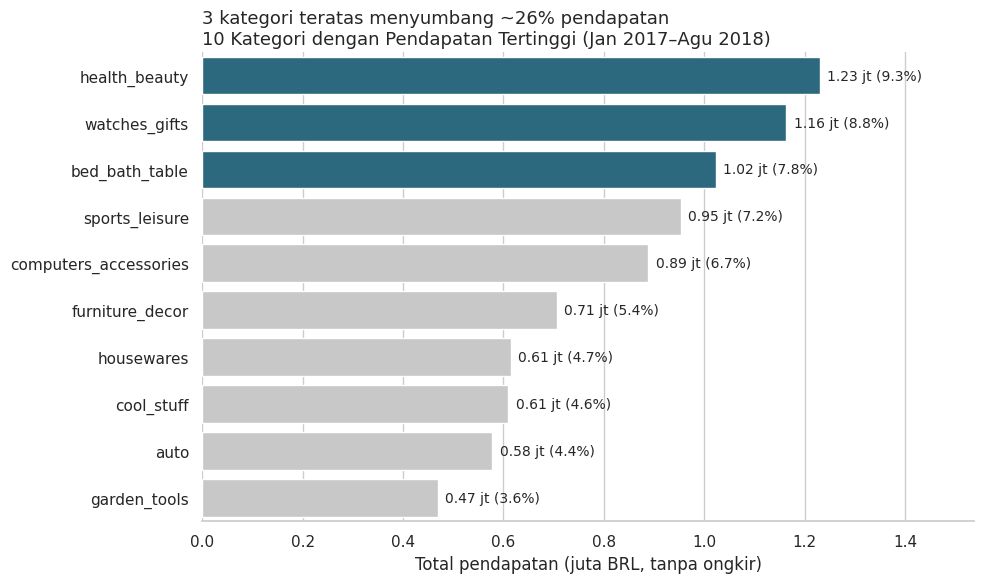

In [110]:
top10 = category_summary.head(10).reset_index()
colors = [MAIN_COLOR] * 3 + [GREY] * 7

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top10, y="product_category", x="pendapatan", hue="product_category", palette=colors, legend=False, ax=ax)
for i, (val, pct) in enumerate(zip(top10["pendapatan"], top10["porsi_pendapatan_%"])):
    ax.text(val + 15000, i, f"{val / 1e6:.2f} jt ({pct:.1f}%)", va="center", fontsize=10)
ax.set_title("3 kategori teratas menyumbang ~26% pendapatan\n10 Kategori dengan Pendapatan Tertinggi (Jan 2017–Agu 2018)", fontsize=13, loc="left")
ax.set_xlabel("Total pendapatan (juta BRL, tanpa ongkir)")
ax.set_ylabel(None)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}"))
ax.set_xlim(0, top10["pendapatan"].max() * 1.25)
sns.despine(left=True)
plt.tight_layout()
plt.show()

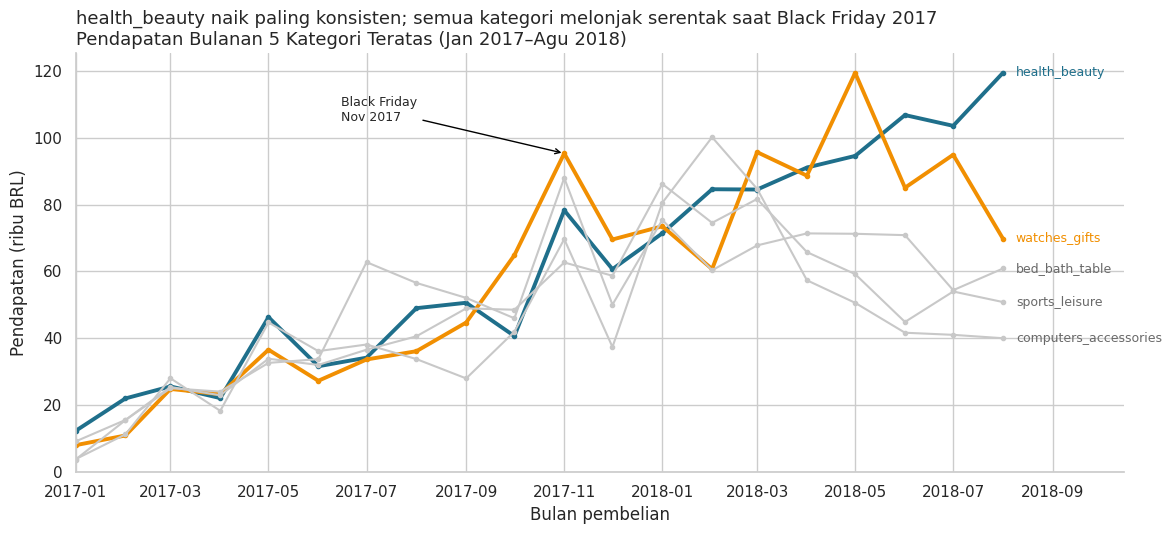

In [111]:
trend_df = (
    item_df[item_df["product_category"].isin(top5_categories)]
    .groupby([item_df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp(), "product_category"])["price"]
    .sum()
    .unstack()
)

fig, ax = plt.subplots(figsize=(12, 5.5))
palette = {cat: GREY for cat in top5_categories}
palette["health_beauty"] = MAIN_COLOR
palette["watches_gifts"] = "#F18F01"
for cat in top5_categories:
    lw = 2.8 if cat in ("health_beauty", "watches_gifts") else 1.5
    ax.plot(trend_df.index, trend_df[cat], color=palette[cat], linewidth=lw, marker="o", markersize=3)
    label_color = palette[cat] if palette[cat] != GREY else "dimgray"
    ax.text(trend_df.index[-1] + pd.Timedelta(days=8), trend_df[cat].iloc[-1], cat, color=label_color, va="center", fontsize=9)

ax.annotate("Black Friday\nNov 2017", xy=(pd.Timestamp("2017-11-01"), trend_df.loc["2017-11-01"].max()),
            xytext=(pd.Timestamp("2017-06-15"), 105000), arrowprops=dict(arrowstyle="->", color="black"), fontsize=9)
ax.set_title("health_beauty naik paling konsisten; semua kategori melonjak serentak saat Black Friday 2017\nPendapatan Bulanan 5 Kategori Teratas (Jan 2017–Agu 2018)", fontsize=13, loc="left")
ax.set_xlabel("Bulan pembelian")
ax.set_ylabel("Pendapatan (ribu BRL)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:.0f}"))
ax.set_ylim(0, None)
ax.set_xlim(trend_df.index[0], trend_df.index[-1] + pd.Timedelta(days=75))
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Wilayah dengan masalah pengiriman dan dampaknya pada skor ulasan

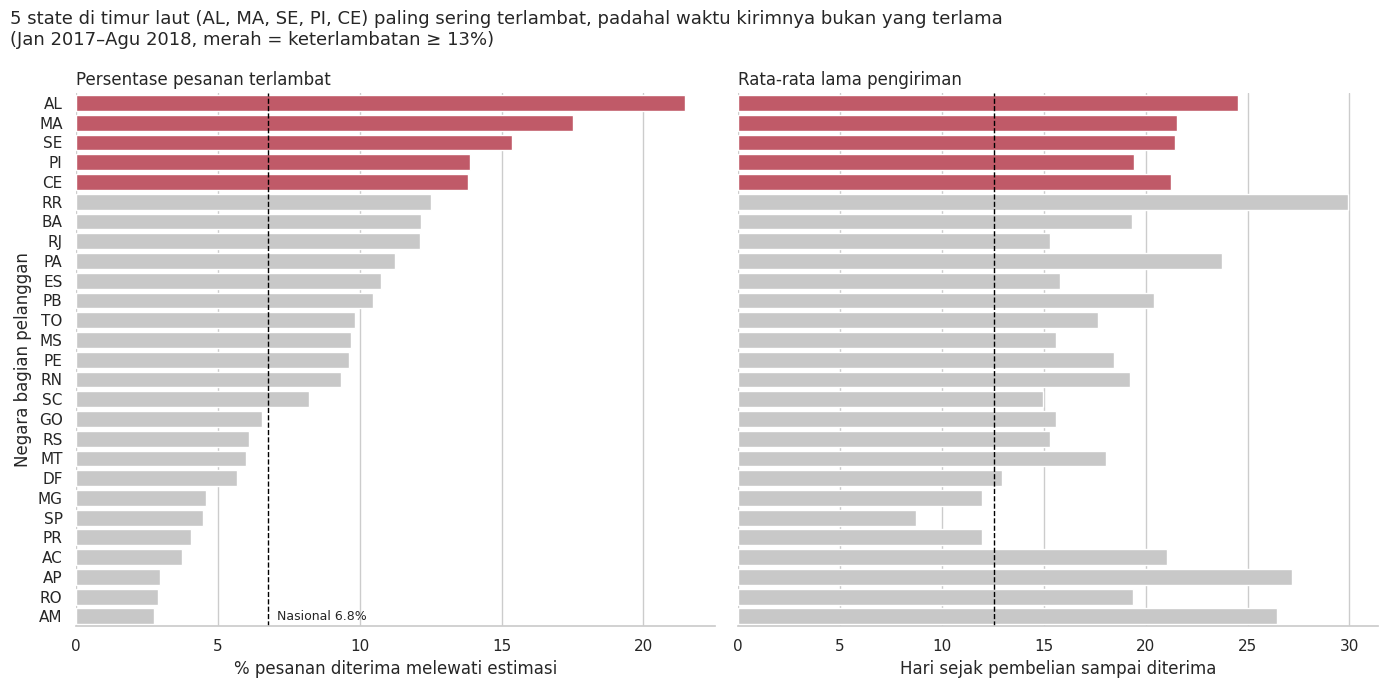

In [112]:
plot_state = state_summary.sort_values("persen_terlambat", ascending=False).reset_index()
national_late = order_df["is_late"].mean() * 100
colors = [ALERT if v >= 13 else GREY for v in plot_state["persen_terlambat"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
sns.barplot(data=plot_state, y="customer_state", x="persen_terlambat", hue="customer_state", palette=colors, legend=False, ax=axes[0])
axes[0].axvline(national_late, color="black", linestyle="--", linewidth=1)
axes[0].text(national_late + 0.3, len(plot_state) - 1, f"Nasional {national_late:.1f}%", fontsize=9, va="center")
axes[0].set_title("Persentase pesanan terlambat", loc="left")
axes[0].set_xlabel("% pesanan diterima melewati estimasi")
axes[0].set_ylabel("Negara bagian pelanggan")

sns.barplot(data=plot_state, y="customer_state", x="rata2_hari_kirim", hue="customer_state", palette=colors, legend=False, ax=axes[1])
axes[1].axvline(order_df["delivery_days"].mean(), color="black", linestyle="--", linewidth=1)
axes[1].set_title("Rata-rata lama pengiriman", loc="left")
axes[1].set_xlabel("Hari sejak pembelian sampai diterima")
axes[1].set_ylabel(None)

fig.suptitle("5 state di timur laut (AL, MA, SE, PI, CE) paling sering terlambat, padahal waktu kirimnya bukan yang terlama\n(Jan 2017–Agu 2018, merah = keterlambatan ≥ 13%)",
             fontsize=13, x=0.01, ha="left")
sns.despine(left=True)
plt.tight_layout()
plt.show()

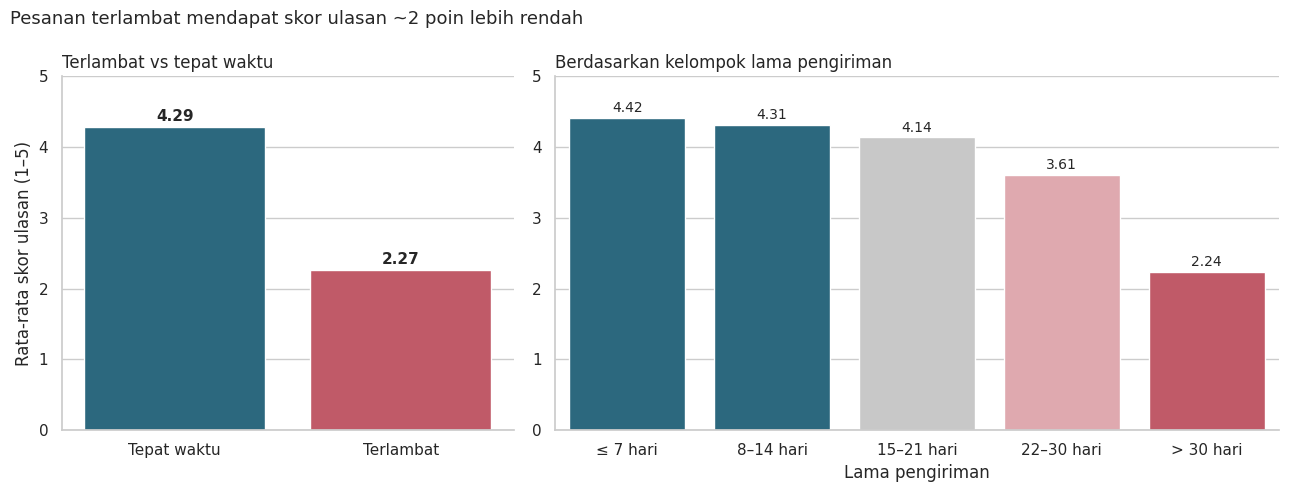

In [113]:
order_df["kelompok_lama_kirim"] = pd.cut(
    order_df["delivery_days"], bins=[0, 7, 14, 21, 30, np.inf],
    labels=["≤ 7 hari", "8–14 hari", "15–21 hari", "22–30 hari", "> 30 hari"],
)
bin_review = order_df.groupby("kelompok_lama_kirim", observed=True)["review_score"].mean()
late_score = order_df.groupby("is_late")["review_score"].mean().rename({False: "Tepat waktu", True: "Terlambat"})

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.6]})
sns.barplot(x=late_score.index, y=late_score.values, hue=late_score.index, palette=[MAIN_COLOR, ALERT], legend=False, ax=axes[0])
for i, v in enumerate(late_score.values):
    axes[0].text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=11, fontweight="bold")
axes[0].set_title("Terlambat vs tepat waktu", loc="left")
axes[0].set_ylabel("Rata-rata skor ulasan (1–5)")
axes[0].set_xlabel(None)
axes[0].set_ylim(0, 5)

bin_colors = [MAIN_COLOR, MAIN_COLOR, GREY, "#E8A0A8", ALERT]
sns.barplot(x=bin_review.index.astype(str), y=bin_review.values, hue=bin_review.index.astype(str), palette=bin_colors, legend=False, ax=axes[1])
for i, v in enumerate(bin_review.values):
    axes[1].text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=10)
axes[1].set_title("Berdasarkan kelompok lama pengiriman", loc="left")
axes[1].set_ylabel(None)
axes[1].set_xlabel("Lama pengiriman")
axes[1].set_ylim(0, 5)

fig.suptitle("Pesanan terlambat mendapat skor ulasan ~2 poin lebih rendah", fontsize=13, x=0.01, ha="left")
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**

**Pertanyaan 1**

- Tiga kategori teratas (`health_beauty`, `watches_gifts`, dan `bed_bath_table`) menyumbang 25,9% dari total pendapatan.
- Kelima kategori teratas mengalami kenaikan penjualan pada November 2017 saat Black Friday.
- Sejak Maret 2018, `health_beauty` dan `watches_gifts` menjadi penyumbang pendapatan terbesar. `health_beauty` tumbuh lebih stabil hingga mencapai nilai tertinggi pada Agustus 2018, sedangkan `watches_gifts` lebih naik turun dan `computers_accessories` mengalami penurunan.

**Pertanyaan 2**

- AL, MA, SE, PI, dan CE memiliki keterlambatan pengiriman 2–3 kali lebih tinggi dari rata-rata nasional. Hal ini kemungkinan disebabkan oleh estimasi pengiriman yang terlalu singkat atau kinerja kurir di wilayah tersebut.
- Pesanan terlambat memiliki rata-rata skor ulasan 2,27, sedangkan pesanan tepat waktu mencapai 4,29.
- Skor ulasan tetap di atas 4 untuk pengiriman hingga 21 hari. Setelah itu, skor mulai turun dan mencapai 2,24 untuk pengiriman lebih dari 30 hari.

## Analisis Lanjutan (Opsional)

In [114]:
# 1. RFM Analysis
# Recency: Jumlah hari sejak pelanggan terakhir kali berbelanja, dihitung dari satu hari setelah tanggal pembelian terakhir dalam data.
# Frequency: Jumlah pesanan yang dilakukan setiap pelanggan.
# Monetary: Total pembayaran pelanggan, termasuk ongkos kirim (ongkir).
# Identitas pelanggan menggunakan customer_unique_id karena customer_id berbeda untuk setiap pesanan.
reference_date = order_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = order_df.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("payment_value", "sum"),
).reset_index()
rfm_df["recency"] = (reference_date - rfm_df["last_purchase"]).dt.days
rfm_df = rfm_df.drop(columns="last_purchase")

print("Jumlah pelanggan unik:", len(rfm_df))
print("Distribusi frequency:")
print(rfm_df["frequency"].value_counts().sort_index().head(6))
print(f"\nPelanggan yang hanya belanja sekali: {(rfm_df['frequency'] == 1).mean() * 100:.1f}%")
rfm_df[["recency", "frequency", "monetary"]].describe()

Jumlah pelanggan unik: 93096
Distribusi frequency:
frequency
1    90307
2     2562
3      180
4       28
5        9
6        5
Name: count, dtype: int64

Pelanggan yang hanya belanja sekali: 97.0%


,recency,frequency,monetary
count,"93,096.00","93,096.00","93,096.00"
mean,236.71,1.03,165.15
std,150.94,0.21,226.39
min,1.00,1.00,9.59
25%,114.00,1.00,63.03
50%,218.00,1.00,107.78
75%,345.00,1.00,182.47
max,602.00,15.00,"13,664.08"


In [115]:
# Skor: R (1-4) = kuartil recency, 4 = paling baru | F (1-3) = 1x, 2x, >=3x | M (1-4) = kuartil total belanja
# Segmen (aturan bisnis):
#   Pelanggan Setia                 : F >= 2 dan R >= 3
#   Setia tapi Mulai Pasif          : F >= 2 dan R <= 2
#   Pelanggan Bernilai Tinggi Baru  : F = 1, M = 4, R >= 3
#   Pelanggan Baru                  : F = 1, M < 4, R >= 3
#   Pelanggan Bernilai Tinggi Tidur : F = 1, M = 4, R <= 2
#   Pelanggan Tidur                 : F = 1, M < 4, R <= 2
rfm_df["R"] = pd.qcut(rfm_df["recency"], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["F"] = rfm_df["frequency"].clip(upper=3)
rfm_df["M"] = pd.qcut(rfm_df["monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)

def segmen_rfm(row):
    if row["F"] >= 2:
        return "Pelanggan Setia" if row["R"] >= 3 else "Setia tapi Mulai Pasif"
    if row["R"] >= 3:
        return "Pelanggan Bernilai Tinggi Baru" if row["M"] == 4 else "Pelanggan Baru"
    return "Pelanggan Bernilai Tinggi Tidur" if row["M"] == 4 else "Pelanggan Tidur"

rfm_df["segment"] = rfm_df.apply(segmen_rfm, axis=1)

segment_summary = rfm_df.groupby("segment").agg(
    jumlah_pelanggan=("customer_unique_id", "count"),
    total_belanja=("monetary", "sum"),
    rata2_recency=("recency", "mean"),
).sort_values("jumlah_pelanggan", ascending=False)
segment_summary["porsi_pelanggan_%"] = segment_summary["jumlah_pelanggan"] / segment_summary["jumlah_pelanggan"].sum() * 100
segment_summary["porsi_belanja_%"] = segment_summary["total_belanja"] / segment_summary["total_belanja"].sum() * 100
segment_summary

,jumlah_pelanggan,total_belanja,rata2_recency,porsi_pelanggan_%,porsi_belanja_%
segment,,,,,
Pelanggan Tidur,34623,"3,054,069.95",361.98,37.19,19.86
Pelanggan Baru,34173,"3,056,878.08",111.53,36.71,19.88
Pelanggan Bernilai Tinggi Baru,10851,"4,224,750.93",111.33,11.66,27.48
Pelanggan Bernilai Tinggi Tidur,10660,"4,178,043.00",363.23,11.45,27.18
Pelanggan Setia,1534,"483,293.03",112.18,1.65,3.14
Setia tapi Mulai Pasif,1255,"377,461.53",350.90,1.35,2.46


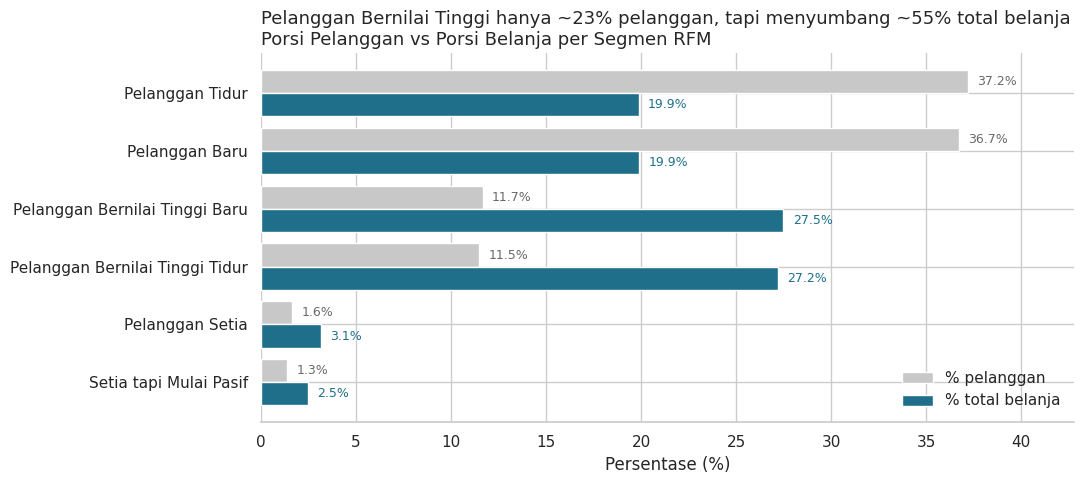

In [116]:
seg_plot = segment_summary.reset_index().sort_values("porsi_pelanggan_%", ascending=True)
y = np.arange(len(seg_plot))

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(y + 0.2, seg_plot["porsi_pelanggan_%"], height=0.4, color=GREY, label="% pelanggan")
ax.barh(y - 0.2, seg_plot["porsi_belanja_%"], height=0.4, color=MAIN_COLOR, label="% total belanja")
for i, (p, b) in enumerate(zip(seg_plot["porsi_pelanggan_%"], seg_plot["porsi_belanja_%"])):
    ax.text(p + 0.5, i + 0.2, f"{p:.1f}%", va="center", fontsize=9, color="dimgray")
    ax.text(b + 0.5, i - 0.2, f"{b:.1f}%", va="center", fontsize=9, color=MAIN_COLOR)
ax.set_yticks(y)
ax.set_yticklabels(seg_plot["segment"])
ax.set_xlabel("Persentase (%)")
ax.set_xlim(0, max(seg_plot["porsi_pelanggan_%"].max(), seg_plot["porsi_belanja_%"].max()) * 1.15)
ax.set_title("Pelanggan Bernilai Tinggi hanya ~23% pelanggan, tapi menyumbang ~55% total belanja\nPorsi Pelanggan vs Porsi Belanja per Segmen RFM", fontsize=13, loc="left")
ax.legend(loc="lower right", frameon=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

In [117]:
# ===== 2. Geospatial Analysis =====
cust_geo = order_df.merge(
    geo_zip_df, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left"
)
print("Pesanan tanpa koordinat:", cust_geo["geolocation_lat"].isna().sum())
cust_geo = cust_geo.dropna(subset=["geolocation_lat"])

geo_state_df = cust_geo.groupby("customer_state").agg(
    lat=("geolocation_lat", "mean"),
    lng=("geolocation_lng", "mean"),
    jumlah_pelanggan=("customer_unique_id", "nunique"),
    pendapatan=("payment_value", "sum"),
).reset_index()
geo_state_df["porsi_pendapatan_%"] = geo_state_df["pendapatan"] / geo_state_df["pendapatan"].sum() * 100
geo_state_df.sort_values("pendapatan", ascending=False).head(8)

Pesanan tanpa koordinat: 265


,customer_state,lat,lng,jumlah_pelanggan,pendapatan,porsi_pendapatan_%
25,SP,-23.17,-47.05,39044,"5,753,502.60",37.53
18,RJ,-22.76,-43.18,11867,"2,044,667.70",13.34
10,MG,-19.92,-44.44,10960,"1,813,369.79",11.83
22,RS,-29.71,-51.95,5146,"858,396.57",5.60
17,PR,-24.81,-50.80,4738,"778,349.76",5.08
23,SC,-27.24,-49.56,3441,"592,707.68",3.87
4,BA,-13.04,-39.47,3147,"589,564.92",3.85
8,GO,-16.61,-49.34,1881,"332,522.92",2.17


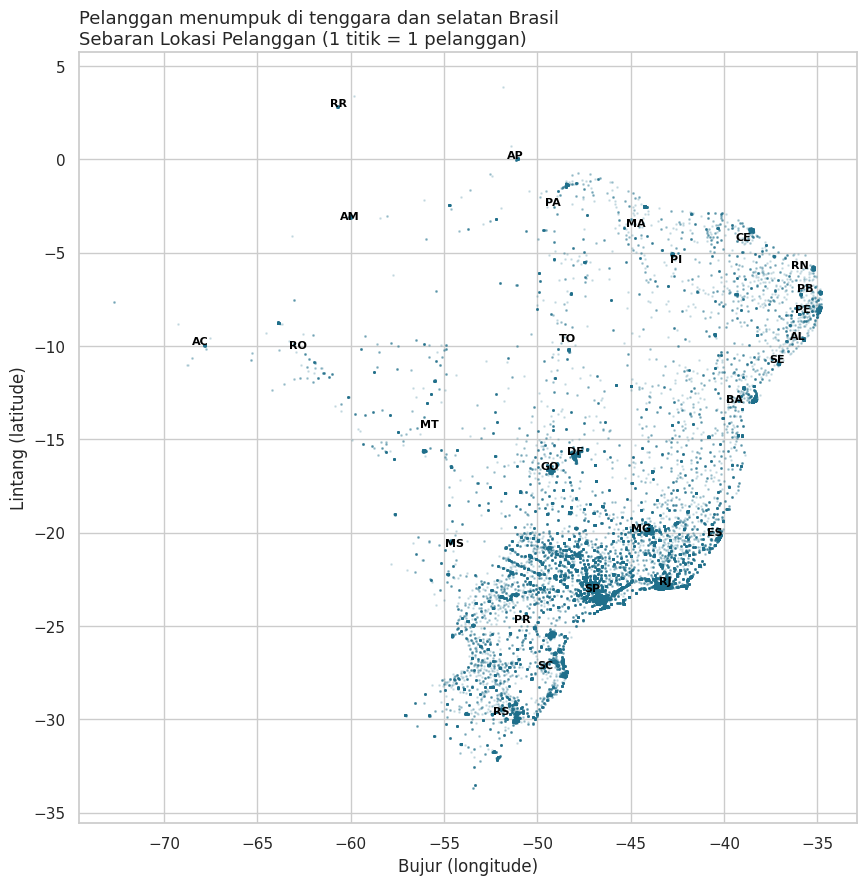

In [118]:
unique_points = cust_geo.drop_duplicates("customer_unique_id")

fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(unique_points["geolocation_lng"], unique_points["geolocation_lat"], s=1, alpha=0.15, color=MAIN_COLOR)
for _, row in geo_state_df.iterrows():
    ax.text(row["lng"], row["lat"], row["customer_state"], fontsize=8, ha="center", fontweight="bold", color="black")
ax.set_title("Pelanggan menumpuk di tenggara dan selatan Brasil\nSebaran Lokasi Pelanggan (1 titik = 1 pelanggan)", fontsize=13, loc="left")
ax.set_xlabel("Bujur (longitude)")
ax.set_ylabel("Lintang (latitude)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [119]:
# Peta interaktif: ukuran lingkaran = pendapatan, merah = state dengan keterlambatan >= 13%
peta = folium.Map(
    location=[-14.5, -51], zoom_start=4,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
)
late_lookup = state_summary["persen_terlambat"].to_dict()
for _, row in geo_state_df.iterrows():
    late = late_lookup.get(row["customer_state"], 0)
    folium.CircleMarker(
        location=[row["lat"], row["lng"]],
        radius=4 + (row["pendapatan"] / geo_state_df["pendapatan"].max()) ** 0.5 * 30,
        color=ALERT if late >= 13 else MAIN_COLOR,
        fill=True, fill_opacity=0.6,
        tooltip=(f"{row['customer_state']}: pendapatan {row['pendapatan']:,.0f} BRL "
                 f"({row['porsi_pendapatan_%']:.1f}%), terlambat {late:.1f}%"),
    ).add_to(peta)
peta

In [120]:
# 3. Clustering manual (binning) berdasarkan total belanja
# Batas kelompok ditentukan dari sebaran data (median ~108 BRL, kuartil atas ~182 BRL), lalu dibulatkan.
rfm_df["kelompok_belanja"] = pd.cut(
    rfm_df["monetary"], bins=[0, 100, 300, 1000, np.inf],
    labels=["Rendah (<100)", "Menengah (100–300)", "Tinggi (300–1.000)", "Premium (>1.000)"],
)
spend_summary = rfm_df.groupby("kelompok_belanja", observed=True).agg(
    jumlah_pelanggan=("customer_unique_id", "count"),
    total_belanja=("monetary", "sum"),
)
spend_summary["porsi_pelanggan_%"] = spend_summary["jumlah_pelanggan"] / spend_summary["jumlah_pelanggan"].sum() * 100
spend_summary["porsi_belanja_%"] = spend_summary["total_belanja"] / spend_summary["total_belanja"].sum() * 100
spend_summary

,jumlah_pelanggan,total_belanja,porsi_pelanggan_%,porsi_belanja_%
kelompok_belanja,,,,
Rendah (<100),43135,"2,603,632.31",46.33,16.93
Menengah (100–300),39665,"6,584,437.20",42.61,42.83
Tinggi (300–1.000),9148,"4,367,488.53",9.83,28.41
Premium (>1.000),1148,"1,818,938.48",1.23,11.83


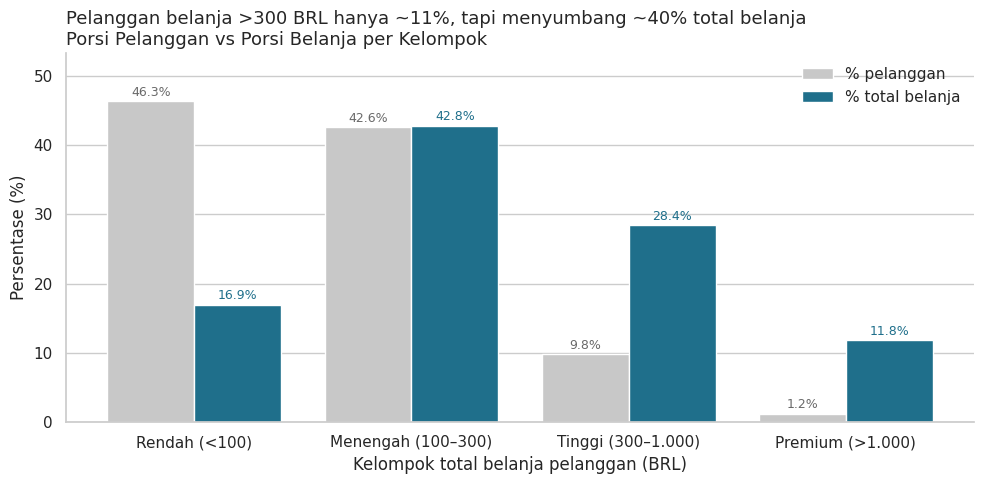

In [121]:
plot_spend = spend_summary.reset_index()
x = np.arange(len(plot_spend))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - 0.2, plot_spend["porsi_pelanggan_%"], width=0.4, color=GREY, label="% pelanggan")
ax.bar(x + 0.2, plot_spend["porsi_belanja_%"], width=0.4, color=MAIN_COLOR, label="% total belanja")
for i, (p, b) in enumerate(zip(plot_spend["porsi_pelanggan_%"], plot_spend["porsi_belanja_%"])):
    ax.text(i - 0.2, p + 0.8, f"{p:.1f}%", ha="center", fontsize=9, color="dimgray")
    ax.text(i + 0.2, b + 0.8, f"{b:.1f}%", ha="center", fontsize=9, color=MAIN_COLOR)
ax.set_xticks(x)
ax.set_xticklabels(plot_spend["kelompok_belanja"].astype(str))
ax.set_xlabel("Kelompok total belanja pelanggan (BRL)")
ax.set_ylabel("Persentase (%)")
ax.set_ylim(0, max(plot_spend["porsi_pelanggan_%"].max(), plot_spend["porsi_belanja_%"].max()) * 1.15)
ax.grid(axis="x", visible=False)
ax.set_title("Pelanggan belanja >300 BRL hanya ~11%, tapi menyumbang ~40% total belanja\nPorsi Pelanggan vs Porsi Belanja per Kelompok", fontsize=13, loc="left")
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

In [122]:
# Menyimpan data bersih untuk dashboard
os.makedirs("dashboard", exist_ok=True)
main_data = item_df[["order_id", "order_item_id", "product_category", "price", "freight_value"]].merge(
    order_df[[
        "order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp",
        "delivery_days", "is_late", "review_score", "payment_value",
    ]],
    on="order_id", how="left",
)
main_data["delivery_days"] = main_data["delivery_days"].round(2)
main_data.to_csv("dashboard/main_data.csv", index=False)
geo_state_df[["customer_state", "lat", "lng"]].to_csv("dashboard/geo_state.csv", index=False)
print(main_data.shape)
main_data.head()

(109872, 12)


,order_id,order_item_id,product_category,price,freight_value,customer_unique_id,customer_state,order_purchase_timestamp,delivery_days,is_late,review_score,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,cool_stuff,58.90,13.29,871766c5855e863f6eccc05f988b23cb,RJ,2017-09-13 08:59:02,7.61,False,5.00,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,pet_shop,239.90,19.93,eb28e67c4c0b83846050ddfb8a35d051,SP,2017-04-26 10:53:06,16.22,False,4.00,259.83
2,000229ec398224ef6ca0657da4fc703e,1,furniture_decor,199.00,17.87,3818d81c6709e39d06b2738a8d3a2474,MG,2018-01-14 14:33:31,7.95,False,5.00,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,perfumery,12.99,12.79,af861d436cfc08b2c2ddefd0ba074622,SP,2018-08-08 10:00:35,6.15,False,4.00,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,garden_tools,199.90,18.14,64b576fb70d441e8f1b2d7d446e483c5,SP,2017-02-04 13:57:51,25.11,False,5.00,218.04


**Insight:**

*RFM Analysis*\
**Tujuan:** mengelompokkan pelanggan berdasarkan waktu terakhir belanja (*recency*), jumlah pembelian (*frequency*), dan total belanja (*monetary*) untuk menentukan strategi pemasaran yang sesuai.

- **97% pelanggan (90.307 dari 93.096) hanya berbelanja satu kali.** Artinya, bisnis masih bergantung pada pelanggan baru dan perlu meningkatkan pembelian ulang.
- Segmen **Pelanggan Bernilai Tinggi Baru** dan **Pelanggan Bernilai Tinggi Tidur** hanya mencakup sekitar 23% pelanggan, tetapi menyumbang 55% dari total belanja.
- Segmen **Pelanggan Setia** hanya 1,7% pelanggan, tetapi menyumbang 3,1% belanja. Artinya, pelanggan yang berbelanja berulang cenderung memberikan nilai lebih besar.
- Sekitar 10,7 ribu pelanggan bernilai tinggi sudah hampir setahun tidak berbelanja, dengan rata-rata *recency* 363 hari. Mereka menjadi target utama untuk menarik pelanggan kembali (*win-back campaign*).

*Geospatial Analysis*\
**Tujuan:** melihat persebaran pelanggan dan pendapatan di setiap wilayah untuk mengetahui wilayah dengan pasar terbesar dan terkecil.

- Pelanggan paling banyak berada di wilayah tenggara (SP, RJ, MG) dan selatan (RS, PR, SC). **SP menyumbang 37,5% pendapatan**, sedangkan tiga state teratas menyumbang 62,7%.
- Wilayah utara dan tengah-barat memiliki jumlah pelanggan yang sangat sedikit.
- Wilayah dengan keterlambatan pengiriman tertinggi berada di timur laut. Pendapatannya masih cukup besar sehingga perbaikan pengiriman di wilayah ini berpeluang meningkatkan pendapatan.

*Clustering Manual (Binning)*\
**Tujuan:** mengelompokkan pelanggan berdasarkan total belanja menjadi Rendah (1.000 BRL) menggunakan batas nilai yang mudah dipahami tanpa algoritma *machine learning*.

- Kelompok **Rendah** memiliki pelanggan terbanyak (46,3%), tetapi hanya menyumbang 16,9% dari total belanja.
- Kelompok **Tinggi** dan **Premium** hanya sekitar 11% pelanggan, tetapi menyumbang sekitar **40% total belanja**. Kedua kelompok ini penting untuk dipertahankan, misalnya melalui layanan prioritas atau gratis ongkir.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1:** Pendapatan masih didominasi 10 kategori teratas yang menyumbang 62,5% dari total pendapatan. `health_beauty` (1,23 juta BRL) dan `watches_gifts` (1,16 juta BRL) menjadi penyumbang terbesar sekaligus kategori dengan pertumbuhan tertinggi dari 2017 ke 2018. Penjualan semua kategori teratas juga meningkat saat Black Friday pada November 2017.
- **Conclusion Pertanyaan 2:** Keterlambatan paling banyak terjadi di timur laut Brasil, terutama AL (21,5%), MA (17,5%), SE (15,4%), PI dan CE (13,9%). Angka ini sekitar 2–3 kali rata-rata nasional (6,8%). Sementara itu, wilayah utara memiliki waktu pengiriman paling lama, tetapi jarang mengalami keterlambatan. Pesanan terlambat juga memiliki skor ulasan lebih rendah (2,27 dibandingkan 4,29). Hal ini menunjukkan bahwa pelanggan lebih memperhatikan ketepatan waktu pengiriman daripada lamanya pengiriman.
- **Temuan Analisis Lanjutan:** Sebanyak 97% pelanggan hanya berbelanja satu kali. Pelanggan Bernilai Tinggi yang mencakup sekitar 23% dari seluruh pelanggan menyumbang 55% total belanja. Pendapatan juga terkonsentrasi di wilayah tenggara, dengan SP menyumbang 37,5% dari total pendapatan.

**Rekomendasi Action Item:**

- **Prioritaskan stok dan promosi&#x20;**`health_beauty`**&#x20;dan&#x20;**`watches_gifts`, serta siapkan kampanye Black Friday untuk lima kategori teratas.
- **Perbaiki pengiriman di AL, MA, SE, PI, dan CE** dengan mengevaluasi kurir dan menyesuaikan estimasi waktu pengiriman agar lebih sesuai dengan kondisi sebenarnya.
- **Buat sistem peringatan keterlambatan** dengan mengirimkan notifikasi atau voucher kepada pelanggan sebelum pesanan terlambat.
- **Tingkatkan pembelian ulang melalui program retensi**, seperti voucher pembelian kedua untuk Pelanggan Bernilai Tinggi Baru dan kampanye *win-back* untuk Pelanggan Bernilai Tinggi Tidur.